## Bussiness Problem : 

* Group nearby delivery locations into clusters so that a delivery company can organize its deliveries more efficiently.
* Suppose an e-commerce company receives 12 delivery orders across a city. The delivery locations are scattered across different areas.
* Instead of assigning all 12 orders randomly to delivery staff, we can use a clustering algorithm to group nearby locations.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"D:\Delivery_Location_Clustering\data\delivery_locations_800.csv")
df.head()

,Delivery_ID,Latitude,Longitude
0,D0001,20.288922,85.824275
1,D0002,20.292178,85.836406
2,D0003,20.298035,85.826724
3,D0004,20.290718,85.820873
4,D0005,20.296763,85.824665


In [3]:
df.shape

(800, 3)

In [4]:
df.columns.tolist()

['Delivery_ID', 'Latitude', 'Longitude']

* Delivery_ID : It is a unique identifier assigned to each delivery.
* Latitude : Latitude represents the north–south position of a location on Earth.It ranges from -90 to +90 degrees.Positive values represent locations north of the Equator, while negative values represent locations south of it.
* Longitude : Longitude represents the east–west position of a location on Earth.It ranges from -180 to +180 degrees.Positive values generally represent locations east of the Prime Meridian, while negative values represent locations west of it.

In [5]:
df.dtypes

Delivery_ID        str
Latitude       float64
Longitude      float64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Delivery_ID  800 non-null    str    
 1   Latitude     800 non-null    float64
 2   Longitude    800 non-null    float64
dtypes: float64(2), str(1)
memory usage: 18.9 KB


In [7]:
df.isna().sum()

Delivery_ID    0
Latitude       0
Longitude      0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
for col in df.columns.tolist():
    print(col)
    print(df[col].nunique())
    print("\n")

Delivery_ID
800


Latitude
794


Longitude
798




In [10]:
df[['Latitude','Longitude']].duplicated().sum()

np.int64(0)

In [11]:
x = df[['Latitude','Longitude']]

In [12]:
x.shape

(800, 2)

In [21]:
invalid_coordinates =x[(
    ~x["Latitude"].between(-90, 90)
    | ~x["Longitude"].between(-180, 180)
)]

In [23]:
invalid_coordinates

,Latitude,Longitude


In [24]:
import matplotlib.pyplot as plt

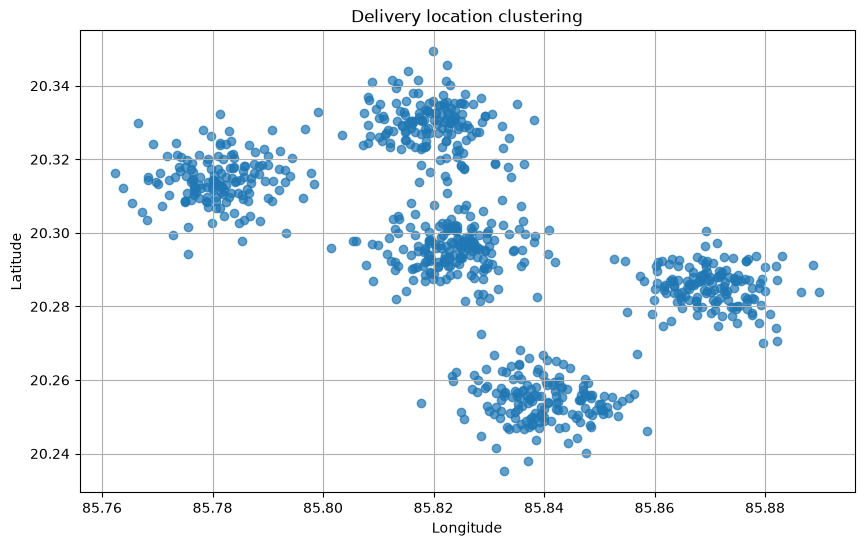

In [29]:
plt.figure(figsize=(10,6))
plt.scatter(x['Longitude'],x['Latitude'],alpha=0.7)
plt.title("Delivery location clustering")
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()

In [30]:
from sklearn.cluster import KMeans

In [31]:
wcss = []
for rr in range(5,min(11,len(x))):
    kmean = KMeans(n_clusters=rr,init='k-means++',random_state=42)
    kmean.fit(x)
    wcss.append(kmean.inertia_)

wcss

[0.06845529504403572,
 0.06295586235025809,
 0.05691460426987457,
 0.05314822975319605,
 0.047646744729909,
 0.0449054154634872]

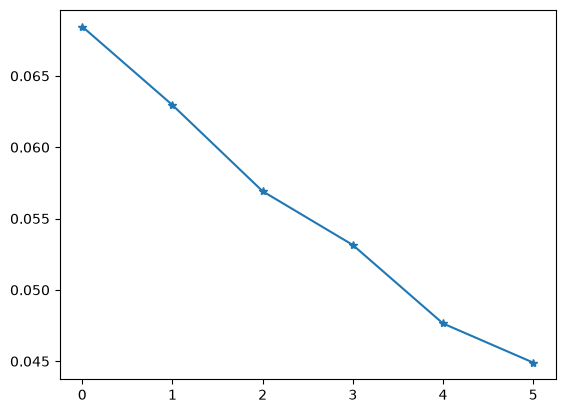

In [33]:
plt.plot(wcss,marker="*")